# Validation of the pose-reliability score on crystal-referenced poses

The pose-reliability score q = 1/(1+exp(0.9·(RMSD−4.5))) is learned from the cross-docked poses of the pose dataset, for which the true RMSD to the crystal pose of the ligand is known. The activity complexes (Kinodata-3D) have no crystal reference, so the predicted q can only be validated on the cross-docked poses. This notebook evaluates the predicted q of the pose-aware model on the **test poses** of the cross-docking dataset (5 folds, every pose is predicted by the model that did not train on it):

- **Scaffold split:** the ligands of the test poses were not seen in training by either task, so this measures how q generalizes to new ligands.
- **Random split:** other poses of the same ligand (docked into other structures of the same kinase) can be in the pose training set; this is the in-distribution reference.

Two evaluations:
1. **All test poses:** rank correlation between q and the true RMSD, and how well q separates good (RMSD ≤ 2.96 Å, q ≥ 0.8) from bad (RMSD ≥ 6.04 Å, q ≤ 0.2) poses (AUROC: probability that a randomly chosen good pose gets a higher q than a randomly chosen bad pose; 0.5 = no separation).
2. **Within the same kinase–ligand pair:** the poses of one pair share the ligand and the kinase and differ only in the template structure the ligand was docked into. Across all poses, q could separate good from bad poses simply by recognizing ligands or kinases that are easy or hard to dock; within a pair, only the pose itself differs. Per pair (at least 5 poses within one fold): Spearman(q, RMSD) and, for pairs with both good and bad poses, the AUROC of q for good vs bad.

**Data** (`data/pose_reliability/poses_<split>.csv.gz`): one row per test pose: fold, ligand (PDB ligand code), kinase, template structure (PDB id), true RMSD to the crystal pose (Å) and predicted q. Figures and tables are written to `output/pose_reliability/`.

In [1]:
from pathlib import Path
import sys

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "pose_reliability"
OUTPUT = REPO / "analysis_publication" / "output" / "pose_reliability"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()

K_SIG, X0_SIG = 0.9, 4.5
GOOD_RMSD, BAD_RMSD = 2.96, 6.04       # q = 0.8 / q = 0.2
MIN_POSES = 5                          # poses per kinase-ligand pair (within one fold) for the within-pair analysis
SPLITS = {"scaffold": ("Scaffold split", "-"), "random": ("Random split", "--")}


def auroc(score, positive):
    # P(score of a positive > score of a negative), ties counted half (Mann-Whitney)
    score, positive = np.asarray(score, dtype=float), np.asarray(positive, dtype=bool)
    n1 = positive.sum(); n0 = len(positive) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(score)
    return (r[positive].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


data = {}
for split in SPLITS:
    d = pd.read_csv(DATA / f"poses_{split}.csv.gz")
    d["pair"] = d["ligand"] + "|" + d["kinase"]
    d["group"] = d["fold"].astype(str) + "|" + d["pair"]   # a pair within one fold (one model)
    d["class"] = np.select([d.true_rmsd <= GOOD_RMSD, d.true_rmsd >= BAD_RMSD], ["good", "bad"], "medium")
    data[split] = d
pd.DataFrame({split: {"test poses": len(d), "ligands": d.ligand.nunique(), "kinases": d.kinase.nunique(),
                      "kinase-ligand pairs (within fold)": d.group.nunique(),
                      "fraction good / medium / bad": " / ".join(f"{(d['class'] == c).mean():.2f}" for c in ["good", "medium", "bad"])}
              for split, d in data.items()})

,scaffold,random
test poses,29248,33920
ligands,704,1399
kinases,100,117
kinase-ligand pairs (within fold),774,6228
fraction good / medium / bad,0.46 / 0.26 / 0.28,0.46 / 0.27 / 0.27


## 1. All test poses

Per fold and pooled: Spearman(q, true RMSD) (negative: higher q for lower RMSD), AUROC of q for good vs bad poses, and the share of poses that the model predicts as good / bad compared with the true shares.

In [2]:
def pose_metrics(g):
    good, bad = (g["class"] == "good").to_numpy(), (g["class"] == "bad").to_numpy()
    sel = good | bad
    return {"poses": len(g), "Spearman(q, RMSD)": stats.spearmanr(g["q"], g["true_rmsd"]).correlation,
            "AUROC good vs bad": auroc(g["q"].to_numpy()[sel], good[sel]),
            "predicted good": (g["q"] >= 0.8).mean(), "true good": good.mean(),
            "predicted bad": (g["q"] <= 0.2).mean(), "true bad": bad.mean()}


rows = []
for split, d in data.items():
    for fold, g in list(d.groupby("fold")) + [("pooled", d)]:
        rows.append({"split": split, "fold": fold, **pose_metrics(g)})
overall = pd.DataFrame(rows)
overall.to_csv(OUTPUT / "q_vs_true_rmsd_per_fold.csv", index=False)
overall.set_index(["split", "fold"]).round(3)

poses  Spearman(q, RMSD)  AUROC good vs bad  predicted good  \
split    fold                                                                  
scaffold 0        7040             -0.166              0.600           0.356   
         1        5792             -0.469              0.779           0.131   
         2        5312             -0.393              0.766           0.130   
         3        5632             -0.356              0.748           0.195   
         4        5472             -0.398              0.756           0.180   
         pooled  29248             -0.364              0.727           0.206   
random   0        6784             -0.761              0.944           0.360   
         1        6784             -0.749              0.941           0.433   
         2        6784             -0.744              0.938           0.346   
         3        6784             -0.763              0.943           0.340   
         4        6784             -0.753              0.947           0.333   
         pooled  33920             -0.752              0.942           0.362   

                 true good  predicted bad  true bad  
split    fold                                        
scaffold 0           0.496          0.104     0.276  
         1           0.424          0.290     0.335  
         2           0.469          0.164     0.272  
         3           0.461          0.127     0.237  
         4           0.444          0.196     0.283  
         pooled      0.460          0.173     0.281  
random   0           0.453          0.230     0.276  
         1           0.465          0.183     0.264  
         2           0.458          0.217     0.270  
         3           0.452          0.249     0.278  
         4           0.456          0.211     0.267  
         pooled      0.457          0.218     0.271

In [3]:
# mean +- sd over the five folds
cols = ["Spearman(q, RMSD)", "AUROC good vs bad"]
per_fold = overall[overall.fold != "pooled"]
agg = per_fold.groupby("split", sort=False)[cols].agg(["mean", "std"])
pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in cols})

,"Spearman(q, RMSD)",AUROC good vs bad
split,,
scaffold,-0.357 ± 0.114,0.730 ± 0.073
random,-0.754 ± 0.008,0.943 ± 0.003


## 2. Within kinase–ligand pairs

Per pair: Spearman(q, RMSD) over its poses (pairs with at least 5 poses and at least 3 distinct RMSD values) and, for pairs with both good and bad poses, the AUROC of q for good vs bad. Reported: number of pairs, median and mean over pairs, fraction of pairs in which q ranks the poses in the right direction, and a Wilcoxon signed-rank test against no relation (Spearman 0, AUROC 0.5).

In [4]:
def within_pairs(d):
    rows = []
    for key, g in d.groupby("group"):
        if len(g) < MIN_POSES or g["true_rmsd"].nunique() < 3 or g["q"].nunique() < 2:
            continue
        good, bad = (g["class"] == "good").to_numpy(), (g["class"] == "bad").to_numpy()
        rows.append({"group": key, "poses": len(g), "RMSD range (A)": g["true_rmsd"].max() - g["true_rmsd"].min(),
                     "Spearman(q, RMSD)": stats.spearmanr(g["q"], g["true_rmsd"]).correlation,
                     "AUROC good vs bad": auroc(g["q"].to_numpy()[good | bad], good[good | bad]) if good.any() and bad.any() else np.nan})
    return pd.DataFrame(rows).set_index("group")


wp = {split: within_pairs(d) for split, d in data.items()}
rows = []
for split, w in wp.items():
    for c, null, better in [("Spearman(q, RMSD)", 0.0, np.less), ("AUROC good vs bad", 0.5, np.greater)]:
        v = w[c].dropna()
        rows.append({"split": split, "metric": c, "pairs": len(v), "median": v.median(), "mean": v.mean(),
                     "fraction of pairs in the right direction": better(v, null).mean(),
                     "Wilcoxon p": stats.wilcoxon(v - null).pvalue,
                     "median poses per pair": w.loc[v.index, "poses"].median(), "median RMSD range (A)": w.loc[v.index, "RMSD range (A)"].median()})
within = pd.DataFrame(rows)
within.to_csv(OUTPUT / "q_within_pairs.csv", index=False)
within.round(3).assign(**{"Wilcoxon p": within["Wilcoxon p"].map("{:.1e}".format)})

,split,metric,pairs,median,mean,fraction of pairs in the right direction,Wilcoxon p,median poses per pair,median RMSD range (A)
0,scaffold,"Spearman(q, RMSD)",667,-0.273,-0.242,0.748,1.5e-50,27.0,7.758
1,scaffold,AUROC good vs bad,570,0.750,0.704,0.802,2.5e-50,29.0,8.086
2,random,"Spearman(q, RMSD)",2251,-0.536,-0.457,0.870,2.5e-289,8.0,6.053
3,random,AUROC good vs bad,1547,1.000,0.889,0.913,1.4e-241,9.0,6.849


## Figure

(a) Mean predicted q per 0.5 Å bin of the true RMSD (test poses, folds pooled), with the training target q(RMSD) (red dashed). Shading: good (≤ 2.96 Å) and bad (≥ 6.04 Å) poses. (b) Spearman(q, true RMSD) within each kinase–ligand pair; negative values: the poses closer to the crystal pose get a higher q.

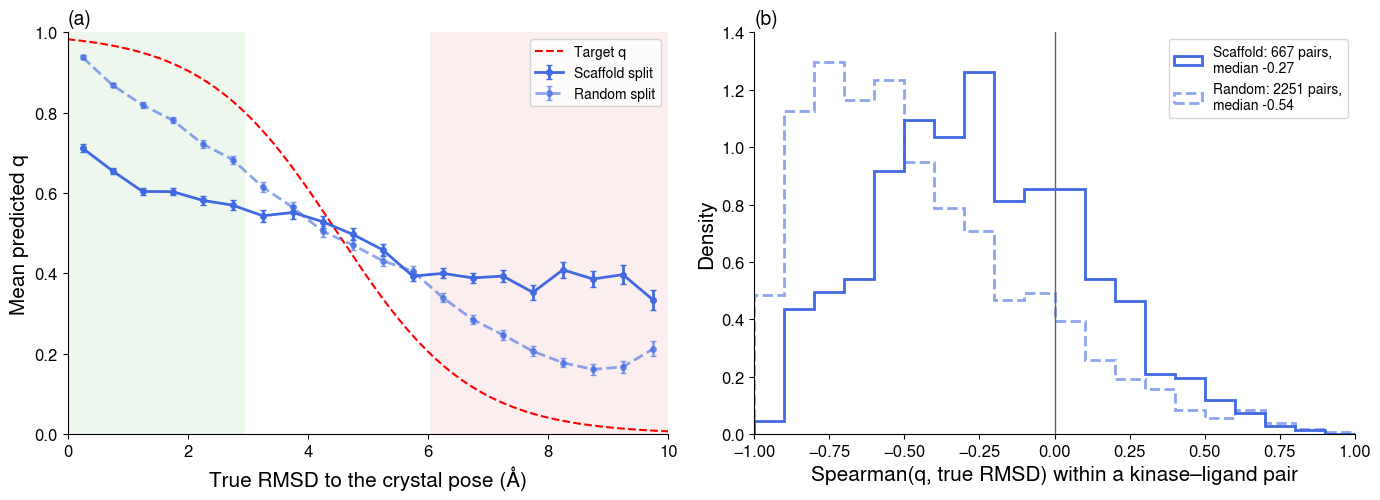

In [5]:
bins = np.arange(0, 10.01, 0.5)
centers = (bins[:-1] + bins[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.axvspan(0, GOOD_RMSD, color=COLORS["good"], alpha=0.08, lw=0)
ax.axvspan(BAD_RMSD, 10, color=COLORS["bad"], alpha=0.08, lw=0)
r = np.linspace(0, 10, 300)
ax.plot(r, 1 / (1 + np.exp(K_SIG * (r - X0_SIG))), "--", color=COLORS["diagonal"], lw=1.5, label="Target q")
for split, (name, ls) in SPLITS.items():
    d = data[split]
    b = pd.cut(d["true_rmsd"], bins, include_lowest=True)
    m = d.groupby(b, observed=False)["q"].agg(["mean", "std", "size"])
    ax.errorbar(centers, m["mean"], yerr=1.96 * m["std"] / np.sqrt(m["size"]), fmt="o" + ls, ms=4, capsize=2,
                color=COLORS["pose_aware"], alpha=1 if split == "scaffold" else 0.6, label=name)
ax.set(xlim=(0, 10), ylim=(0, 1), xlabel="True RMSD to the crystal pose (Å)", ylabel="Mean predicted q")
ax.set_title("(a)", loc="left")
ax.legend(loc="upper right", fontsize=10)

ax = axes[1]
for split, (name, ls) in SPLITS.items():
    v = wp[split]["Spearman(q, RMSD)"].dropna()
    ax.hist(v, bins=np.arange(-1, 1.001, 0.1), density=True, histtype="step", lw=2, ls=ls, color=COLORS["pose_aware"],
            alpha=1 if split == "scaffold" else 0.6, label=f"{split.capitalize()}: {len(v)} pairs,\nmedian {v.median():+.2f}")
ax.axvline(0, color="0.4", lw=1)
ax.set(xlim=(-1, 1), xlabel="Spearman(q, true RMSD) within a kinase–ligand pair", ylabel="Density")
ax.set_title("(b)", loc="left")
ax.legend(loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT / "pose_reliability_validation.png", dpi=600)
plt.show()